In [1]:
import pandas as pd
import seaborn as sns
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import math
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, Dataset

import platform, sys

# --- Détection de la machine ---
IN_COLAB = "google.colab" in sys.modules
IS_MAC = platform.system() == "Darwin"
print(f"Machine : {platform.system()} {platform.machine()} | Colab : {IN_COLAB}")

if IS_MAC:
    # Version Mac (Apple Silicon -> GPU via MPS)
    print(torch.backends.mps.is_available())   # should print True
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
else:
    # Version CUDA (Colab / PC avec GPU NVIDIA)
    print(torch.cuda.is_available())      # should print True
    if torch.cuda.is_available():
        print(torch.cuda.get_device_name(0))
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("device =", device)

Machine : Darwin arm64 | Colab : False
True
device = mps


In [2]:
PATH = "fall-2026-ecse-551-task-1"

train = pd.read_csv(PATH+"/train.csv")
test = pd.read_csv(PATH+"/test.csv")

Y_train = train["label_name"]
X_train = train["image_path"]
X_test = test["id"]

def clean_path(path) :
  clean_path = path[7:]
  clean_path = "archive/RIVAL10_Kaggle" + clean_path
  return clean_path

def clean_path_test(path):
  path = "archive/RIVAL10_Kaggle/test/test_images/" + path
  return path

X_train = X_train.apply(clean_path)
X_test = X_test.apply(clean_path_test)

print(X_train)
print(X_test)
print(Y_train)

FileNotFoundError: [Errno 2] No such file or directory: 'fall-2026-ecse-551-task-1/train.csv'

# Checking stats about the data

label_name
frog      2127
bird      2126
car       2126
cat       2122
equine    2122
ship      2119
dog       2119
deer      2116
plane     2110
truck     2011
Name: count, dtype: int64

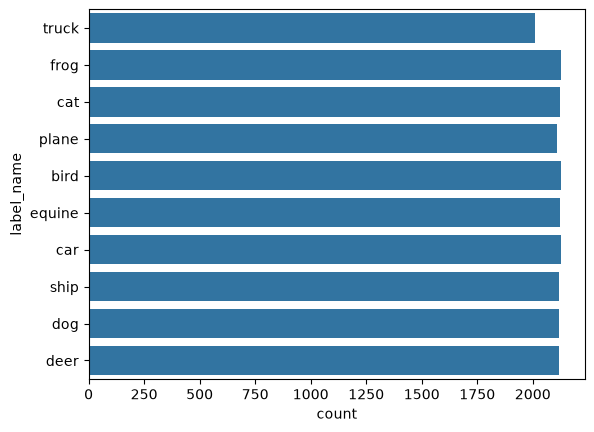

In [14]:
g = sns.countplot(Y_train)

Y_train.value_counts()

In [15]:
def read_image(path) :
  return np.array(Image.open(PATH+"/"+path).convert("RGB"))


In [16]:
(X_train == "").any()
#check no test has null

np.False_

In [17]:
print(read_image(X_train[0]).shape)
print(read_image(X_train[0]).max())
print(read_image(X_train[0]).min())

(224, 224, 3)
255
0


# Prepare Data for pytorch

In [18]:
#Prepare Data
X_train = X_train.apply(read_image)
X_test = X_test.apply(read_image)

In [19]:
encodings={
    "truck":0,
    "frog":1,
    "cat":2,
    "plane":3,
    "bird":4,
    "car":5,
    "equine":6,
    "ship":7,
    "deer":8,
    "dog":9,
}

reverse_encodings = {v: k for k, v in encodings.items()}

Y_train = Y_train.replace(encodings)

In [20]:
class ImageDataset(Dataset):
    def __init__(self, images, labels=None):
        self.images = list(images)   # works for a list, an array or a pandas Series
        self.labels = labels

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        x = torch.from_numpy(np.asarray(self.images[i])).permute(2, 0, 1).float() / 255
        if self.labels is None:
            return x
        return x, self.labels[i]

Y_train = torch.from_numpy(Y_train.astype("int64").to_numpy())

train_loader = DataLoader(ImageDataset(X_train, Y_train), batch_size=64, shuffle=True)
test_loader  = DataLoader(ImageDataset(X_test), batch_size=64, shuffle=False)

In [ ]:
import torchvision.transforms.v2 as T
augment = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(), T.ColorJitter(0.2, 0.2, 0.2)])
class AugmentedDataset(ImageDataset):
    def __getitem__(self, i): x, y = super().__getitem__(i); return augment(x), y
train_loader = DataLoader(AugmentedDataset(X_train, Y_train), batch_size=64, shuffle=True)  # le test n'est pas augmenté

# Define Model

In [ ]:
config = {
    "image_size": 224,
    "patch_size": 16,        # 196 patches ; patch 8 = 784 tokens, ~16x plus lent pour l'attention
    "num_channels": 3,
    "hidden_size": 256,
    "hidden_dropout_prob": 0.1,
    "intermediate_size": 1024,
    "num_attention_heads": 4,
    "num_classes": 10,
    "num_hidden_layers": 6,
}


class PatchEmbeddings(nn.Module):
    
    def __init__(self, config):
        super().__init__()
        self.image_size = config["image_size"]
        self.num_channels = config["num_channels"]
        self.patch_size = config["patch_size"]
        self.hidden_size = config["hidden_size"] #dimension de nos vecteurs de patch embeddings Q, K, V
        self.num_patches = (self.image_size // self.patch_size) ** 2
        #Sride et patch size pour diviser notre image en n patchs sans overlap.
        #Chaque patch est projeté convolvé pour avoir une projection de dimension hidden_size
        self.projection = nn.Conv2d(in_channels=self.num_channels, out_channels=self.hidden_size, kernel_size=self.patch_size, stride=self.patch_size) 
        
    def forward(self, x):
        # (batch_size, num_channels, image_size, image_size) -> (batch_size, num_patches, hidden_size)
        x = self.projection(x)
        #(B, hidden, n, n) --> (B, n*n, 768)
        x = x.flatten(2).transpose(1, 2) #
        return x

In [ ]:
def sinusoidal_position_embeddings(n, d):
    P = torch.zeros(n, d)
    i = torch.arange(n).unsqueeze(1)          # positions i (n, 1)
    j = torch.arange(0, d, 2)                 # indices 2j
    P[:, 0::2] = torch.sin(i / 1000 ** (j / d))   # p_{i,2j}
    P[:, 1::2] = torch.cos(i / 1000 ** (j / d))   # p_{i,2j+1}
    return P.unsqueeze(0)                     # (1, n, d)

class Embeddings(nn.Module):
    """
    Ajoute du PE et notre classe token à notre emebedding de patchs
    """
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.patch_embeddings = PatchEmbeddings(config)
        self.cls_token = nn.Parameter(torch.randn(1, 1, config["hidden_size"]))
        #Sinusoiadle embeddign sur les patch et le CLS token
        self.position_embeddings = nn.Parameter(
    sinusoidal_position_embeddings(self.patch_embeddings.num_patches + 1, config["hidden_size"]),
    requires_grad=False)

        #self.dropout = nn.Dropout(config["hidden_dropout_prob"])
        
    def forward(self,x):
        x = self.patch_embeddings(x)
        batch_size, _, _ = x.size()
        #On créé le token CLS
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        #On ajoute le token CLS à nos batchs
        x = torch.cat((cls_tokens, x), dim=1)
         #On ajoute notre possitional embedding 
        x = x + self.position_embeddings
        return x

In [ ]:
class AttentionHead(nn.Module):
    #Une tête d'attention qu'on va combiner avec n autres pour créer un block de MHA
    def __init__(self, hidden_size, attention_head_size, bias=False): #dropout à ajouter
        super().__init__()
        #dimension de représentation de chaque token
        self.hidden_size = hidden_size
        #dimension des vecteurs Q, K, V à l'intérieur d'un block d'attention
        self.attention_head_size = attention_head_size
        # Projections des queries, key, values
        self.query = nn.Linear(hidden_size, attention_head_size, bias=bias)
        self.key = nn.Linear(hidden_size, attention_head_size, bias=bias)
        self.value = nn.Linear(hidden_size, attention_head_size, bias=bias)

        #self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # Projection de nos input pour obtenir K, Q, V
        # (batch_size, n_patch+1, hidden_size) -> (batch_size, n_patch+1, attention_head_size=hidden_szoe)
        query = self.query(x)
        key = self.key(x)
        value = self.value(x)
        # Calcul les attention scores en prenant en compte qu'on a choisi des Q, K, V de mêmes dimensinos
        # Scaled dot product attentino
        # softmax(Q*K.T/sqrt(attention_head_size))*V
        attention_scores = torch.matmul(query, key.transpose(-1, -2))
        attention_scores = attention_scores / math.sqrt(self.attention_head_size)
        attention_probs = nn.functional.softmax(attention_scores, dim=-1)
        #attention_probs = self.dropout(attention_probs)
        # Calculate the attention output
        
        #dimension de V 
        attention_output = torch.matmul(attention_probs, value)
        return (attention_output, attention_probs)

In [ ]:
class MultiHeadAttention(nn.Module):
    
    def __init__(self, config):
        super().__init__()
        self.hidden_size = config["hidden_size"]
        #nombre d'attention head qu'on choisit
        self.num_attention_heads = config["num_attention_heads"]
        
        #on coupe nos X dimensions projetées en num_attention_heads chacun de dimensions attention_head_size (division euclidienne car pas garanti d'etre divisible par num_attention head)
        self.attention_head_size = self.hidden_size // self.num_attention_heads
        self.all_head_size = self.num_attention_heads * self.attention_head_size
        #self.qkv_bias = config["qkv_bias"]
        #on créé une liste d'attention heads
        self.heads = nn.ModuleList([])
        
        #on instancie nos attention head blocks
        for _ in range(self.num_attention_heads):
            head = AttentionHead(
                self.hidden_size,
                self.attention_head_size,
            )
            self.heads.append(head)
            
        self.output_projection = nn.Linear(self.all_head_size, self.hidden_size)
        #self.output_dropout = nn.Dropout(config["hidden_dropout_prob"])
        
    def forward(self, x, output_attentions=False):
        # Pour chaque tête : (B, N, hidden) -> (B, N, head_size)
        attention_outputs = [head(x) for head in self.heads]
        
        #concanetaoin des output de chaque attention head
        attention_output = torch.cat([attention_output for attention_output, _ in attention_outputs], dim=-1)
        
        
        attention_output = self.output_projection(attention_output)
        #attention_output = self.output_dropout(attention_output)
        # Return the attention output and the attention probabilities (optional)
        if not output_attentions:
            return (attention_output, None)
        else:
            attention_probs = torch.stack([attention_probs for _, attention_probs in attention_outputs], dim=1)
            return (attention_output, attention_probs)

In [ ]:
class MLP(nn.Module):

    def __init__(self, config) :
        super().__init__()
        self.dense_1 = nn.Linear(config["hidden_size"], config["intermediate_size"])
        self.activation = nn.GELU()
        # le MLP du bloc Transformer garde la dimension hidden_size (pour la connexion résiduelle)
        self.dense_2 = nn.Linear(config["intermediate_size"], config["hidden_size"])
        self.dropout = nn.Dropout(config["hidden_dropout_prob"])

    def forward(self, x):
        x = self.dense_1(x)
        x = self.activation(x)
        x = self.dense_2(x)
        x = self.dropout(x)
        return x


In [ ]:
class Block(nn.Module):
    """Un bloc Transformer (pre-norm) : LN -> MHA -> résiduel, puis LN -> MLP -> résiduel"""
    def __init__(self, config):
        super().__init__()
        self.layernorm_1 = nn.LayerNorm(config["hidden_size"])
        self.attention = MultiHeadAttention(config)
        self.layernorm_2 = nn.LayerNorm(config["hidden_size"])
        self.mlp = MLP(config)

    def forward(self, x):
        attention_output, _ = self.attention(self.layernorm_1(x))
        x = x + attention_output
        x = x + self.mlp(self.layernorm_2(x))
        return x


class ViT(nn.Module):
    """Embeddings -> num_hidden_layers blocs -> LayerNorm -> classification sur le token CLS"""
    def __init__(self, config):
        super().__init__()
        self.embeddings = Embeddings(config)
        self.blocks = nn.ModuleList([Block(config) for _ in range(config["num_hidden_layers"])])
        self.layernorm = nn.LayerNorm(config["hidden_size"])
        self.classifier = nn.Linear(config["hidden_size"], config["num_classes"])

    def forward(self, x):
        # (B, 3, 224, 224) -> (B, num_patches+1, hidden_size)
        x = self.embeddings(x)
        for block in self.blocks:
            x = block(x)
        x = self.layernorm(x)
        # on garde seulement la sortie du token CLS (position 0) : (B, hidden_size) -> (B, num_classes)
        return self.classifier(x[:, 0])


# Train Model

In [ ]:
# ===== Monitoring live : loss + attention maps (9 images) =====
# À exécuter AVANT la cellule d'entraînement. Ne modifie ni les données ni la boucle :
# on "écoute" les appels du modèle et de loss_fn via un hook global PyTorch.
# Pour désactiver : _monitor_handle.remove()
from IPython.display import display

class LiveMonitor:
    def __init__(self, dataset, idx, every=50):
        self.dataset, self.idx, self.every = dataset, idx, every
        self.model = None
        self._busy = False
        self._attn = []

    def _reset(self, model):
        # nouveau modèle (cellule d'entraînement relancée) -> on repart de zéro
        self.model = model
        self.step = 0
        self.step_losses, self.epoch_losses, self._epoch_buf = [], [], []
        self.loss_handle = self.attn_handle = None

    def hook(self, module, inputs, output):
        if self._busy:  # forward interne du monitor : on récupère juste les attention probs
            if isinstance(module, AttentionHead):
                self._attn.append(output[1].detach())
            return
        if isinstance(module, ViT) and module.training and module is not self.model:
            self._reset(module)
        elif isinstance(module, nn.CrossEntropyLoss) and torch.is_grad_enabled() and self.model is not None:
            self._on_loss(output.item())

    def _on_loss(self, loss):
        self.step += 1
        self.step_losses.append(loss)
        self._epoch_buf.append(loss)
        spe = len(train_loader)
        if self.step == 1:
            self.plot_attention()
        if self.step % spe == 0:  # fin d'epoch
            self.epoch_losses.append(float(np.mean(self._epoch_buf)))
            self._epoch_buf = []
            self.plot_loss()
            self.plot_attention()
        elif self.step % self.every == 0:
            self.plot_loss()

    def _show(self, fig, handle):
        if handle is None:
            handle = display(fig, display_id=True)
        else:
            handle.update(fig)
        plt.close(fig)
        return handle

    def plot_loss(self):
        spe = len(train_loader)
        fig, ax = plt.subplots(figsize=(8, 3.5))
        x = np.arange(1, len(self.step_losses) + 1) / spe
        ax.plot(x, self.step_losses, alpha=0.25, lw=0.8, label="loss par batch")
        k = 25
        if len(self.step_losses) >= k:
            smooth = np.convolve(self.step_losses, np.ones(k) / k, mode="valid")
            ax.plot(x[k - 1:], smooth, label=f"moyenne glissante ({k} batchs)")
        if self.epoch_losses:
            ax.plot(np.arange(1, len(self.epoch_losses) + 1), self.epoch_losses, "o-", label="moyenne par epoch")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Train loss"); ax.grid(alpha=0.3); ax.legend()
        self.loss_handle = self._show(fig, self.loss_handle)

    @torch.no_grad()
    def attention_maps(self):
        m = self.model
        x = torch.stack([self.dataset[i][0] for i in self.idx]).to(next(m.parameters()).device)
        was_training = m.training
        m.eval(); self._busy = True; self._attn = []
        try:
            logits = m(x)
        finally:
            self._busy = False
            m.train(was_training)
        L, H = len(m.blocks), len(m.blocks[0].attention.heads)
        A = torch.stack(self._attn).view(L, H, *self._attn[0].shape).mean(1)  # (L, B, N, N), moyenne des têtes
        self._attn = []
        # Attention rollout : on propage l'attention à travers les couches (+ identité pour le résiduel)
        N = A.shape[-1]
        I = torch.eye(N, device=A.device)
        R = I.expand_as(A[0]).clone()
        for a in A:
            a = 0.5 * a + 0.5 * I
            a = a / a.sum(-1, keepdim=True)
            R = a @ R
        g = int(math.sqrt(N - 1))
        maps = R[:, 0, 1:].reshape(-1, g, g).cpu().numpy()  # attention du CLS vers chaque patch
        return x.cpu(), maps, logits.argmax(1).cpu()

    def plot_attention(self):
        x, maps, preds = self.attention_maps()
        fig, axes = plt.subplots(3, 3, figsize=(8, 8.5))
        for ax, img, hm, p, i in zip(axes.flat, x, maps, preds, self.idx):
            y = int(self.dataset[i][1])
            img = np.clip(img.permute(1, 2, 0).numpy(), 0, 1)
            h, w = img.shape[:2]
            hm = (hm - hm.min()) / (hm.max() - hm.min() + 1e-8)
            ax.imshow(img)
            ax.imshow(hm, cmap="jet", alpha=0.45, extent=(0, w, h, 0), interpolation="bilinear")
            ok = int(p) == y
            ax.set_title(f"gt: {reverse_encodings[y]} / pred: {reverse_encodings[int(p)]}",
                         color="green" if ok else "red", fontsize=9)
            ax.axis("off")
        fig.suptitle(f"Attention rollout (CLS) — après {len(self.epoch_losses)} epoch(s)")
        fig.tight_layout()
        self.attn_handle = self._show(fig, self.attn_handle)


# 9 images fixes du train (une par classe 0..8), prises via le même Dataset que l'entraînement
_monitor_idx = [int((Y_train == c).nonzero()[0]) for c in range(9)]

if "_monitor_handle" in globals():
    _monitor_handle.remove()  # évite d'empiler les hooks si on relance la cellule
monitor = LiveMonitor(ImageDataset(X_train, Y_train), _monitor_idx, every=50)
_monitor_handle = torch.nn.modules.module.register_module_forward_hook(monitor.hook)

In [ ]:
model = ViT(config).to(device)

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)

num_epochs = 20
for epoch in range(num_epochs):
    model.train()
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        pbar.set_postfix(loss=f"{loss.item():.4f}")


0 1.5823607444763184
1 1.1023030281066895
2 1.1145808696746826


# Evaluate Model

In [23]:
model.eval()
preds = []
with torch.no_grad():
    for xb in tqdm(test_loader, desc="Prédiction"):
        preds.append(model(xb.to(device)).argmax(dim=1).cpu())
predictions = torch.cat(preds)

In [24]:
predictions = pd.Series(predictions.numpy()).map(reverse_encodings)
for i in range(0,10):
    print(predictions[i])

dog
bird
deer
truck
car
car
plane
ship
dog
bird


In [ ]:
# id = numéro de l'image de test (00000.png -> 0), label = classe prédite
results = pd.DataFrame({
    "id": test["id"].astype(str).str.replace(".png", "", regex=False).astype(int),
    "label": predictions,
})
results.to_csv("results.csv", index=False)
results.head()
